# Beef regression modelling
Run `beef_regression_comparison.py` before refreshing these results. Each held-out animal contributes equally to pooled MAE. Slaughter dates stay together across the ten outer folds.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

results = Path("results/beef_regression_comparison_10fold_animal")
figs = Path("figs/beef_regression_modelling_10fold")
figs.mkdir(exist_ok=True)
scores = pd.read_csv(results / "scores.csv")
pred = pd.read_csv(results / "predictions.csv")
folds = pd.read_csv(results / "fold_scores.csv")
key = ["animal_type","target","model","setting","horizon","pruning"]
assert folds.groupby(key).fold.nunique().eq(10).all() and len(scores) == 306
assert not pred.duplicated(key + ["animal_index"]).any()
targets = ["live weight","carcass weight","price"]
titles = ["Live weight (kg)","Carcass weight (kg)","Indicative price ($)"]
palette = {"heifer":"#5F6F52","steer":"#B99470"}
plt.rcParams.update({"font.family":"serif","legend.frameon":False,"axes.spines.top":False,"axes.spines.right":False})
pruning = "all"  # used for model comparison and interpretation
weather = scores.query("setting == 'Teeth + weather'")
def save(fig, name):
    for ext in ["svg","png"]:
        fig.savefig(figs / f"{name}.{ext}", dpi=300, bbox_inches="tight")
    plt.show()

## Performance overview
Pooled animal-level MAE. Bold marks each model’s minimum across settings. Underlining marks the overall minimum within animal type and target, including the dummy. Ties use the displayed precision. Weather settings include teeth and NZDI.

In [2]:
overview = scores.loc[scores.horizon.eq(0) | scores.pruning.eq(pruning)].copy()
overview["predictors"] = overview.setting
mask = overview.horizon.gt(0)
overview.loc[mask,"predictors"] = overview.loc[mask,"horizon"].astype(str) + " d"
columns = ["Dummy","Teeth only","Teeth + NZDI"] + [f"{h} d" for h in [30,60,120,180]]
table = overview.pivot(index=["animal_type","target","model"], columns="predictors", values="animal_mae")[columns].round(1)
row_min = table.min(axis=1)
overall_min = row_min.groupby(level=["animal_type","target"]).transform("min")
styles = table.eq(row_min,axis=0).map(lambda v: "font-weight:bold;" if v else "")
styles += table.eq(overall_min,axis=0).map(lambda v: "text-decoration:underline;" if v else "")
display(table.style.format("{:.1f}", na_rep="—").apply(lambda _: styles, axis=None))

predictors 
 Dummy 
 Teeth only 
 Teeth + NZDI 
 30 d 
 60 d 
 120 d 
 180 d 
 
 
 animal_type 
 target 
 model 
   
   
   
   
   
   
   
 
 
 
 
 heifer 
 carcass weight 
 Dummy 
 14.2 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 ElasticNet 
 — 
 13.6 
 14.6 
 14.2 
 13.5 
 13.4 
 13.4 
 
 
 ExtraTrees 
 — 
 13.9 
 13.4 
 13.1 
 13.0 
 13.1 
 12.9 
 
 
 HistGradientBoosting 
 — 
 13.6 
 16.1 
 13.6 
 13.4 
 13.7 
 13.6 
 
 
 LightGBM 
 — 
 13.6 
 16.2 
 13.5 
 13.8 
 14.4 
 14.2 
 
 
 RandomForest 
 — 
 13.3 
 13.3 
 12.8 
 12.9 
 13.1 
 12.8 
 
 
 live weight 
 Dummy 
 28.1 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 ElasticNet 
 — 
 25.4 
 26.2 
 29.5 
 27.8 
 28.9 
 29.2 
 
 
 ExtraTrees 
 — 
 25.6 
 28.1 
 30.0 
 29.7 
 29.6 
 30.2 
 
 
 HistGradientBoosting 
 — 
 25.9 
 35.7 
 35.0 
 31.2 
 30.5 
 30.7 
 
 
 LightGBM 
 — 
 25.9 
 35.7 
 33.5 
 30.3 
 30.0 
 28.8 
 
 
 RandomForest 
 — 
 26.2 
 31.6 
 30.1 
 28.5 
 28.6 
 28.7 
 
 
 price 
 Dummy 
 78.9 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 ElasticNet 
 — 
 75.9 
 81.6 
 78.1 
 73.4 
 71.1 
 74.3 
 
 
 ExtraTrees 
 — 
 77.8 
 75.1 
 73.3 
 72.3 
 73.0 
 73.4 
 
 
 HistGradientBoosting 
 — 
 76.2 
 90.1 
 79.4 
 79.1 
 79.0 
 78.6 
 
 
 LightGBM 
 — 
 76.2 
 89.4 
 78.6 
 79.7 
 81.5 
 79.1 
 
 
 RandomForest 
 — 
 74.5 
 74.9 
 72.5 
 72.7 
 72.3 
 71.4 
 
 
 steer 
 carcass weight 
 Dummy 
 17.3 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 ElasticNet 
 — 
 17.3 
 17.2 
 16.0 
 16.0 
 16.0 
 16.0 
 
 
 ExtraTrees 
 — 
 17.7 
 17.5 
 17.0 
 17.1 
 16.5 
 16.5 
 
 
 HistGradientBoosting 
 — 
 17.9 
 19.0 
 18.1 
 17.9 
 16.7 
 16.8 
 
 
 LightGBM 
 — 
 17.9 
 19.0 
 18.2 
 17.9 
 16.6 
 16.4 
 
 
 RandomForest 
 — 
 17.6 
 18.2 
 17.5 
 16.9 
 16.7 
 16.7 
 
 
 live weight 
 Dummy 
 33.8 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 ElasticNet 
 — 
 33.5 
 33.6 
 33.1 
 33.6 
 33.8 
 34.3 
 
 
 ExtraTrees 
 — 
 33.4 
 33.1 
 32.3 
 32.8 
 32.9 
 34.0 
 
 
 HistGradientBoosting 
 — 
 33.0 
 38.6 
 33.2 
 34.3 
 34.3 
 35.2 
 
 
 LightGBM 
 — 
 33.0 
 38.6 
 33.3 
 34.2 
 34.0 
 35.0 
 
 
 RandomForest 
 — 
 33.1 
 35.3 
 31.6 
 32.2 
 32.8 
 34.2 
 
 
 price 
 Dummy 
 100.4 
 — 
 — 
 — 
 — 
 — 
 — 
 
 
 ElasticNet 
 — 
 101.3 
 99.0 
 97.4 
 97.3 
 97.4 
 96.6 
 
 
 ExtraTrees 
 — 
 103.3 
 101.9 
 99.2 
 99.4 
 94.3 
 95.7 
 
 
 HistGradientBoosting 
 — 
 104.5 
 109.3 
 107.3 
 105.5 
 98.2 
 97.3 
 
 
 LightGBM 
 — 
 104.5 
 109.2 
 108.0 
 103.8 
 97.8 
 97.6 
 
 
 RandomForest 
 — 
 103.1 
 105.0 
 103.4 
 100.9 
 95.9 
 96.8

## Model comparison at the best horizon
Each point shows the lowest pooled weather-model MAE across the four fixed horizons under the selected pruning setting. Labels give the horizon in days. Selection on these same held-out scores makes this a descriptive comparison.

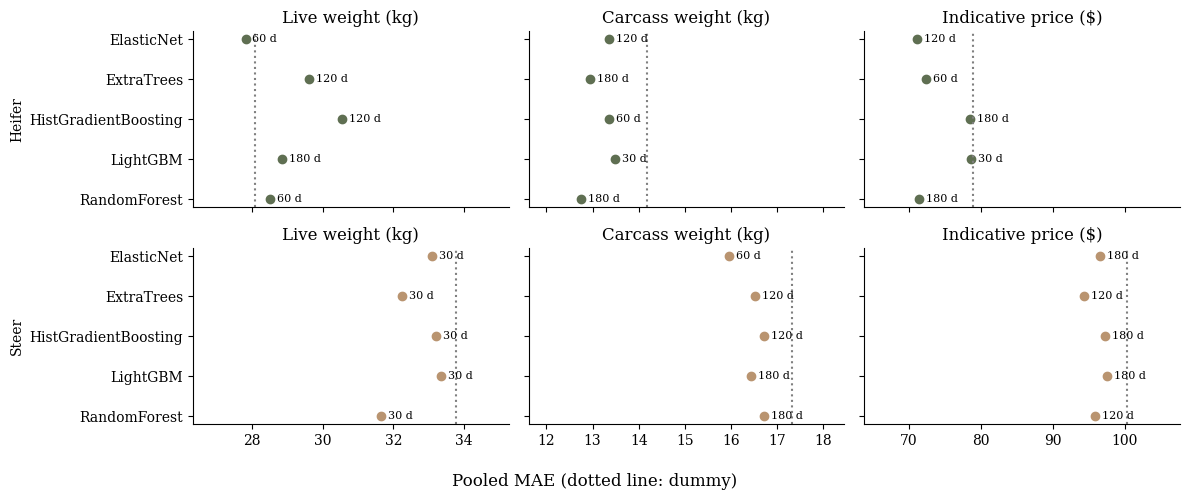

In [3]:
best = weather.query("pruning == @pruning").sort_values(["animal_mae","horizon"]).drop_duplicates(["animal_type","target","model"])
models = sorted(best.model.unique())
fig, axes = plt.subplots(2,3,figsize=(12,5),sharey=True,sharex="col")
for row,(animal,color) in zip(axes,palette.items()):
    for ax,target,title in zip(row,targets,titles):
        vals = best.query("animal_type == @animal and target == @target").set_index("model").loc[models]
        ax.scatter(vals.animal_mae,range(len(models)),color=color)
        for i,r in enumerate(vals.itertuples()):
            ax.annotate(f"{r.horizon} d",(r.animal_mae,i),xytext=(5,0),textcoords="offset points",va="center",fontsize=8)
        dummy = scores.query("animal_type == @animal and target == @target and model == 'Dummy'").animal_mae.item()
        ax.axvline(dummy,color="0.5",ls=":")
        ax.margins(x=.25)
        ax.set(title=title,yticks=range(len(models)),yticklabels=models)
    row[0].set_ylabel(animal.capitalize())
axes[0,0].invert_yaxis()
fig.supxlabel("Pooled MAE (dotted line: dummy)")
fig.tight_layout()
save(fig,"models_best_horizon")

## ElasticNet horizon sensitivity
Each point is pooled animal-level MAE for a fixed maximum weather history. Lower is better. Horizontal lines show the same model using teeth alone or teeth and NZDI.

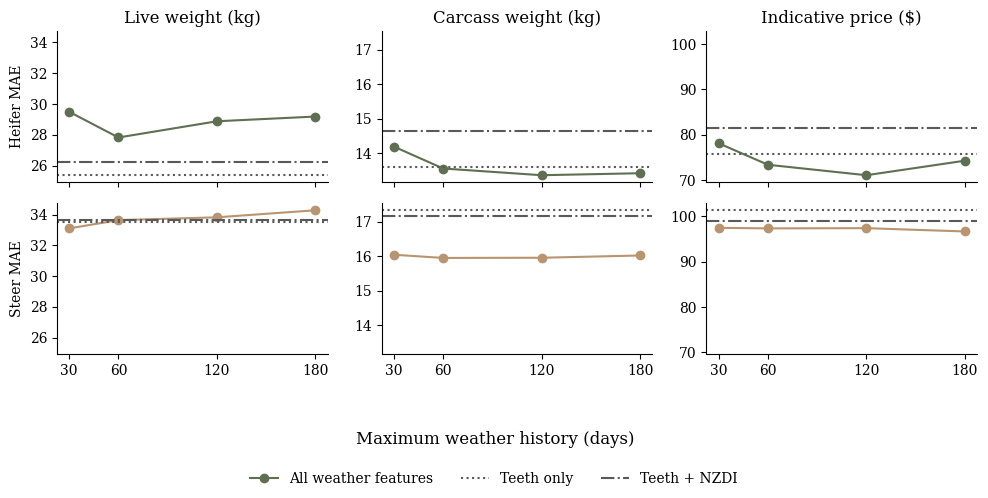

In [4]:
enet = scores.query("model == 'ElasticNet'")
fig, axes = plt.subplots(2, 3, figsize=(10, 5), sharex=True, sharey="col")
for row, (animal, color) in zip(axes, palette.items()):
    for ax, target, title in zip(row, targets, titles):
        sub = enet.query("animal_type == @animal and target == @target")
        curve = sub.loc[sub.pruning.eq(pruning)].sort_values("horizon")
        ax.plot(curve.horizon, curve.animal_mae, color=color, marker="o", label="All weather features")
        for reference, style in [("Teeth only", ":"), ("Teeth + NZDI", "-.")]:
            ax.axhline(sub.loc[sub.setting.eq(reference), "animal_mae"].item(), color="0.35", ls=style, label=reference)
        ax.set_xticks([30, 60, 120, 180])
        if animal == next(iter(palette)):
            ax.set_title(title)
    row[0].set_ylabel(f"{animal.capitalize()} MAE")
fig.supxlabel("Maximum weather history (days)", y=.095)
handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3)
fig.tight_layout(rect=[0,.14,1,1])
save(fig, "elasticnet_horizon_sensitivity")

## Ablation study
Teeth only reports pooled MAE. The other columns give the percentage reduction in MAE relative to teeth only. Positive values indicate improvement.

In [5]:
days = {("heifer","live weight"):120, ("heifer","carcass weight"):60, ("heifer","price"):120,
        ("steer","live weight"):30, ("steer","carcass weight"):120, ("steer","price"):120}
enet = scores.query("model == 'ElasticNet'").copy()
selected = [h == days[a,t] and p == pruning for a,t,h,p in zip(enet.animal_type,enet.target,enet.horizon,enet.pruning)]
abl = enet.loc[enet.horizon.eq(0) | np.asarray(selected)].pivot(index=["animal_type","target"],columns="setting",values="animal_mae")
abl = abl.reindex(pd.MultiIndex.from_product([palette, targets], names=abl.index.names))
table = pd.DataFrame({"Teeth only": abl["Teeth only"],
                      "Teeth+NZDI": 100*(1-abl["Teeth + NZDI"]/abl["Teeth only"]),
                      "Teeth+NZDI+Weather": 100*(1-abl["Teeth + weather"]/abl["Teeth only"])})
labels = dict(zip(targets, titles))
table.index = pd.MultiIndex.from_tuples([(a.capitalize(), labels[t], days[a,t]) for a,t in abl.index],
                                       names=["Animal", "Target", "Days"])
fmt = {col: "{:.1f}" if col == "Teeth only" else "{:+.1f}%" for col in table}
display(table.style.format(fmt))

analysis = Path("results/beef_regression_analysis_10fold_animal")
analysis.mkdir(parents=True, exist_ok=True)
table.to_csv(analysis / "elasticnet_ablation.csv")
latex_fmt = {col: spec.replace("%", r"\%") for col, spec in fmt.items()}
table.style.format(latex_fmt).format_index(escape="latex", axis=0).to_latex(analysis / "elasticnet_ablation.tex", hrules=True,
    label="tab:beef_regression_elasticnet_ablation",
    caption="ElasticNet regression ablation. Teeth only reports pooled MAE. The other columns report percentage reductions in MAE relative to teeth only.")

Teeth only 
 Teeth+NZDI 
 Teeth+NZDI+Weather 
 
 
 Animal 
 Target 
 Days 
   
   
   
 
 
 
 
 Heifer 
 Live weight (kg) 
 120 
 25.4 
 -3.4% 
 -13.8% 
 
 
 Carcass weight (kg) 
 60 
 13.6 
 -7.7% 
 +0.3% 
 
 
 Indicative price ($) 
 120 
 75.9 
 -7.5% 
 +6.3% 
 
 
 Steer 
 Live weight (kg) 
 30 
 33.5 
 -0.3% 
 +1.3% 
 
 
 Carcass weight (kg) 
 120 
 17.3 
 +1.0% 
 +8.0% 
 
 
 Indicative price ($) 
 120 
 101.3 
 +2.3% 
 +3.9%

## Feature importance
Each box summarizes fold changes in MAE after permuting a whole weather family or window across held-out dates. Positive values mean predictions worsened. Each fold contributes once. Whiskers span the full range.

In [6]:
import ast
import re
from itertools import permutations
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from beef_regression_comparison import specs
from threadpoolctl import threadpool_limits

data = pd.read_csv("data/beef_preprocessed.csv").join(pd.read_csv("data/beef_weather_windows.csv"))
family = {"MnTemp(C)":"Air temperature","MnRH(%)":"Relative humidity","MnSpd(mps)":"Wind speed",
          "Rain(mm)":"Rainfall","Average W/m2":"Solar radiation","RadGlb(MJ/m2)":"Solar radiation"}
windows = {"0_4":"1–4","5_10":"5–10","11_20":"11–20","21_30":"21–30","31_60":"31–60","61_120":"61–120","121_180":"121–180"}
changes, coefs = [], []
for (animal,target),h in days.items():
    cohort = data.loc[data["Animal Type"].eq(animal)].dropna(subset=[target])
    select = "animal_type == @animal and target == @target and model == 'ElasticNet' and horizon == @h and pruning == @pruning"
    predictions = pred.query(select)
    for fit in folds.query(select).itertuples():
        held = predictions.loc[predictions.fold.eq(fit.fold)].set_index("animal_index").sort_index()
        test = cohort.loc[held.index]
        train = cohort.drop(held.index)
        numeric = ast.literal_eval(fit.selected_numeric)
        scaler = StandardScaler().fit(train[numeric], sample_weight=np.ones(len(train)))
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(train[["Teeth category"]])
        def design(part):
            return np.column_stack([encoder.transform(part[["Teeth category"]]), scaler.transform(part[numeric])])
        # Reconstruct this fold from its saved features and tuned parameters.
        model = specs()["ElasticNet"][0].set_params(**ast.literal_eval(fit.params))
        with threadpool_limits(limits=1):
            model.fit(design(train),train[target],sample_weight=np.ones(len(train)))
        baseline = model.predict(design(test))
        np.testing.assert_allclose(baseline,held.predicted,atol=1e-7,rtol=0)
        coef = pd.Series(model.coef_[-len(numeric):],index=numeric).drop("NZDI")
        coefs.extend((animal,target,fit.fold,k,v) for k,v in coef.items())
        dates,idx = np.unique(test["kill date"],return_inverse=True)
        effects = pd.DataFrame(scaler.transform(test[numeric]),columns=numeric).drop(columns="NZDI").mul(coef)
        effects = effects.groupby(idx).mean()
        residual = baseline-held.observed.to_numpy()
        fields = coef.index.str.split("__win").str[0]
        labels = [family.get(f,"Wind direction" if f.startswith("Wind_") else "Heat indices") for f in fields]
        bands = [windows[re.search(r"__win(\d+_\d+)_",f)[1]] for f in coef.index]
        for level,labels_,groups in [("Family",labels,sorted(set(family.values())|{"Heat indices","Wind direction"})),
                                    ("Window",bands,[v for k,v in windows.items() if int(k.split("_")[1])<=h])]:
            for group in groups:
                e = effects.loc[:,np.array(labels_)==group].sum(axis=1).to_numpy()
                losses = [np.abs(residual+(e[list(order)]-e)[idx]).mean() for order in permutations(range(len(dates)))]
                changes.append((animal,target,fit.fold,level,group,np.mean(losses)-np.abs(residual).mean()))
importance = pd.DataFrame(changes,columns=["animal","target","fold","level","group","change"])
coefficients = pd.DataFrame(coefs,columns=["animal","target","fold","feature","coef"])

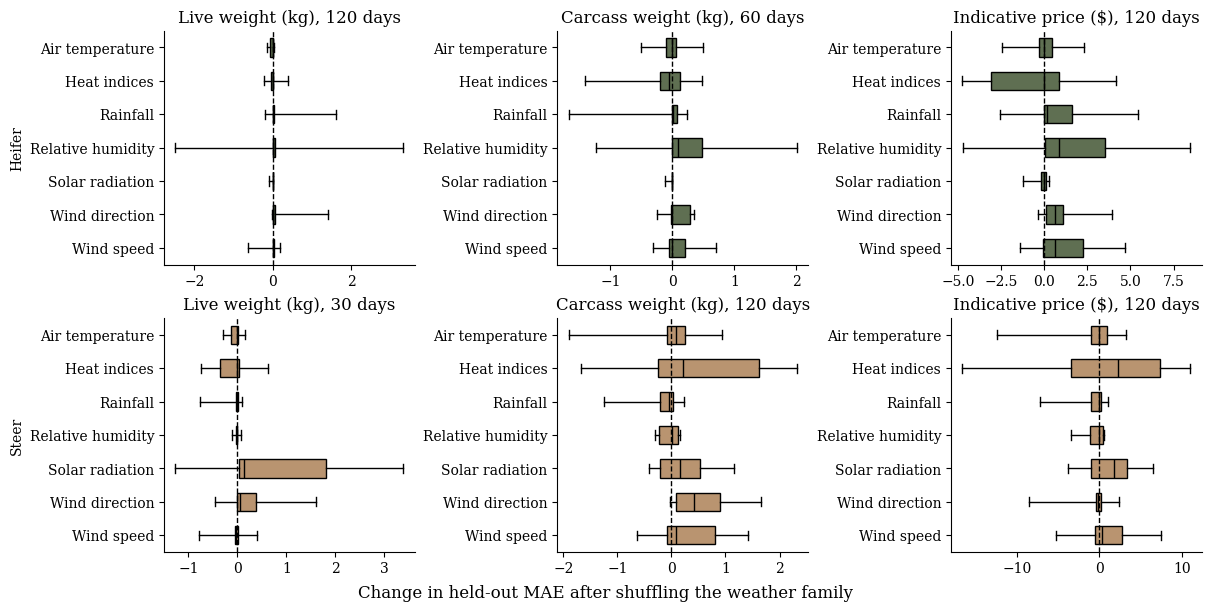

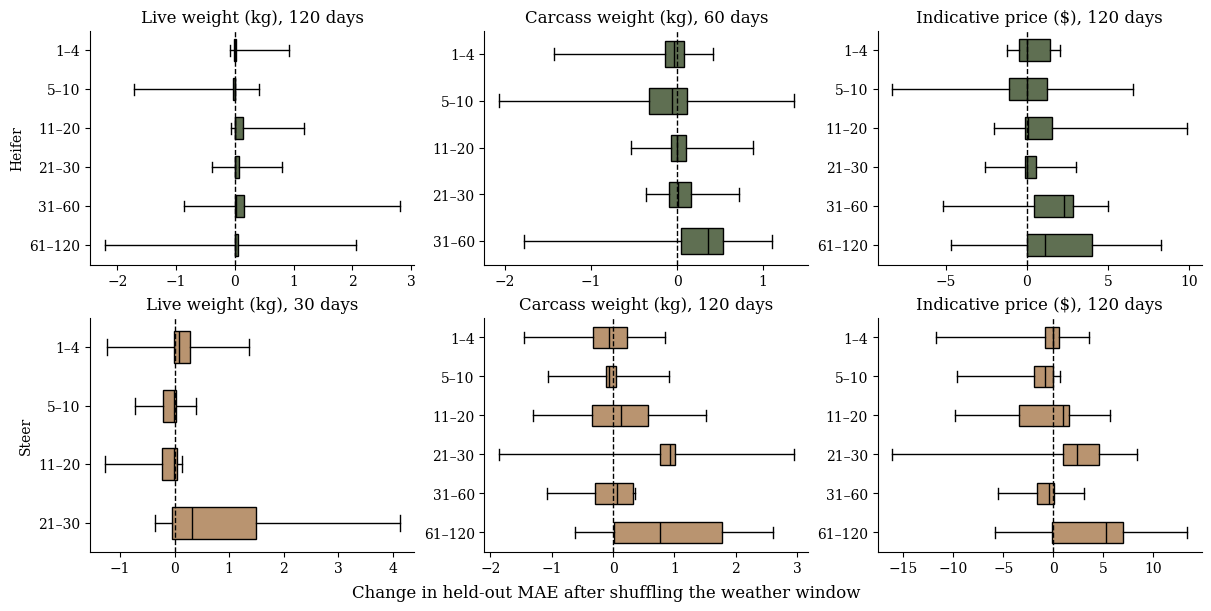

In [7]:
def boxes(ax, groups, labels, color):
    ax.boxplot(groups,orientation="horizontal",widths=.55,whis=(0,100),patch_artist=True,
               boxprops={"facecolor":color},medianprops={"color":"black"},tick_labels=labels)
    ax.axvline(0,color="black",ls="--",lw=1)
    ax.invert_yaxis()

for level in ["Family","Window"]:
    fig,axes = plt.subplots(2,3,figsize=(12,6),layout="constrained")
    for row,(animal,color) in zip(axes,palette.items()):
        for ax,target,title in zip(row,targets,titles):
            sub = importance.query("animal == @animal and target == @target and level == @level")
            grouped = sub.groupby("group",sort=False).change
            labels = list(grouped.groups)
            boxes(ax,[grouped.get_group(k) for k in labels],labels,color)
            ax.set_title(f"{title}, {days[animal,target]} days")
        row[0].set_ylabel(animal.capitalize())
    fig.supxlabel(f"Change in held-out MAE after shuffling the weather {level.lower()}")
    save(fig,f"elasticnet_importance_{level.lower()}")

## Coefficient directions
A positive coefficient means a one-training-SD increase in that feature raises the fitted outcome (kg or dollars), holding the other predictors fixed. Each panel shows up to 12 features retained in at least five folds, ranked by absolute mean coefficient across retaining folds.

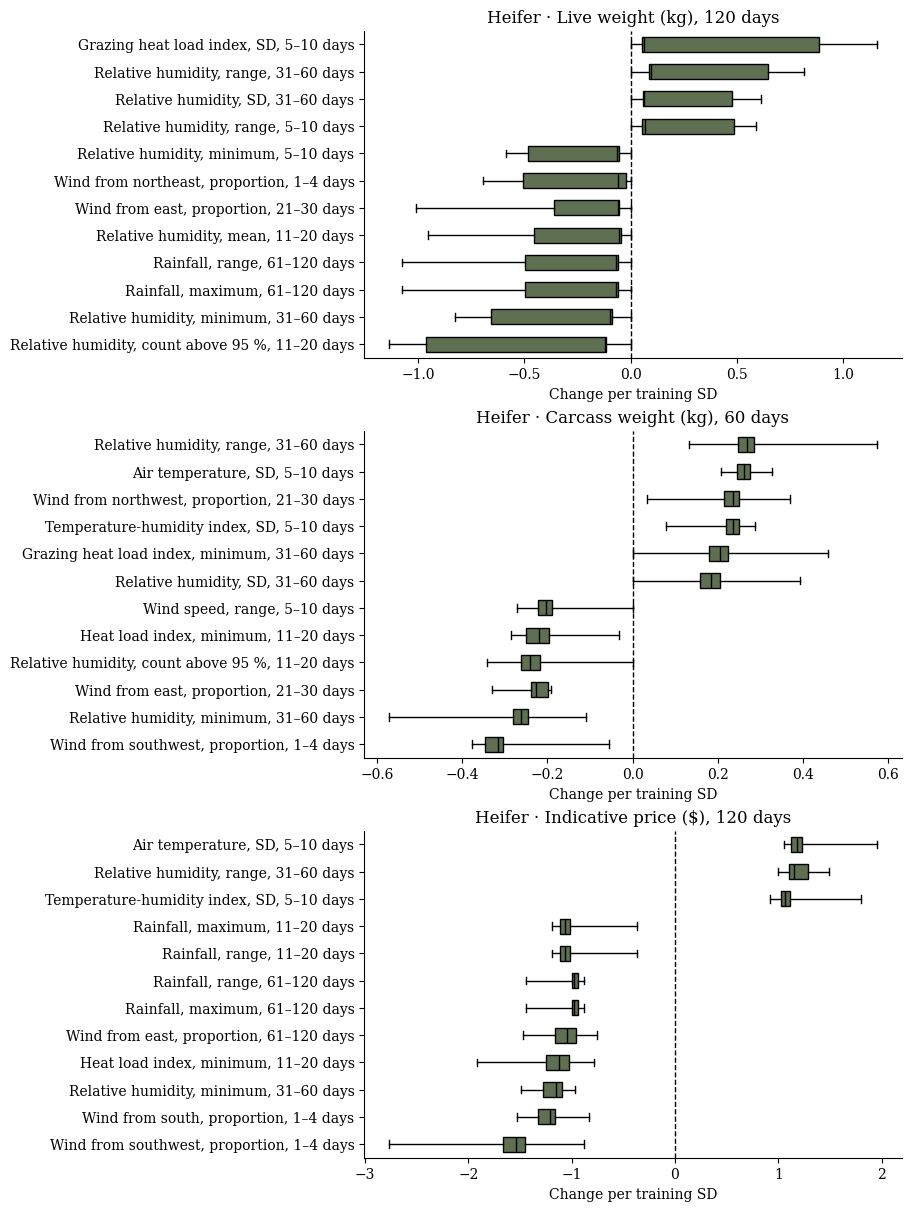

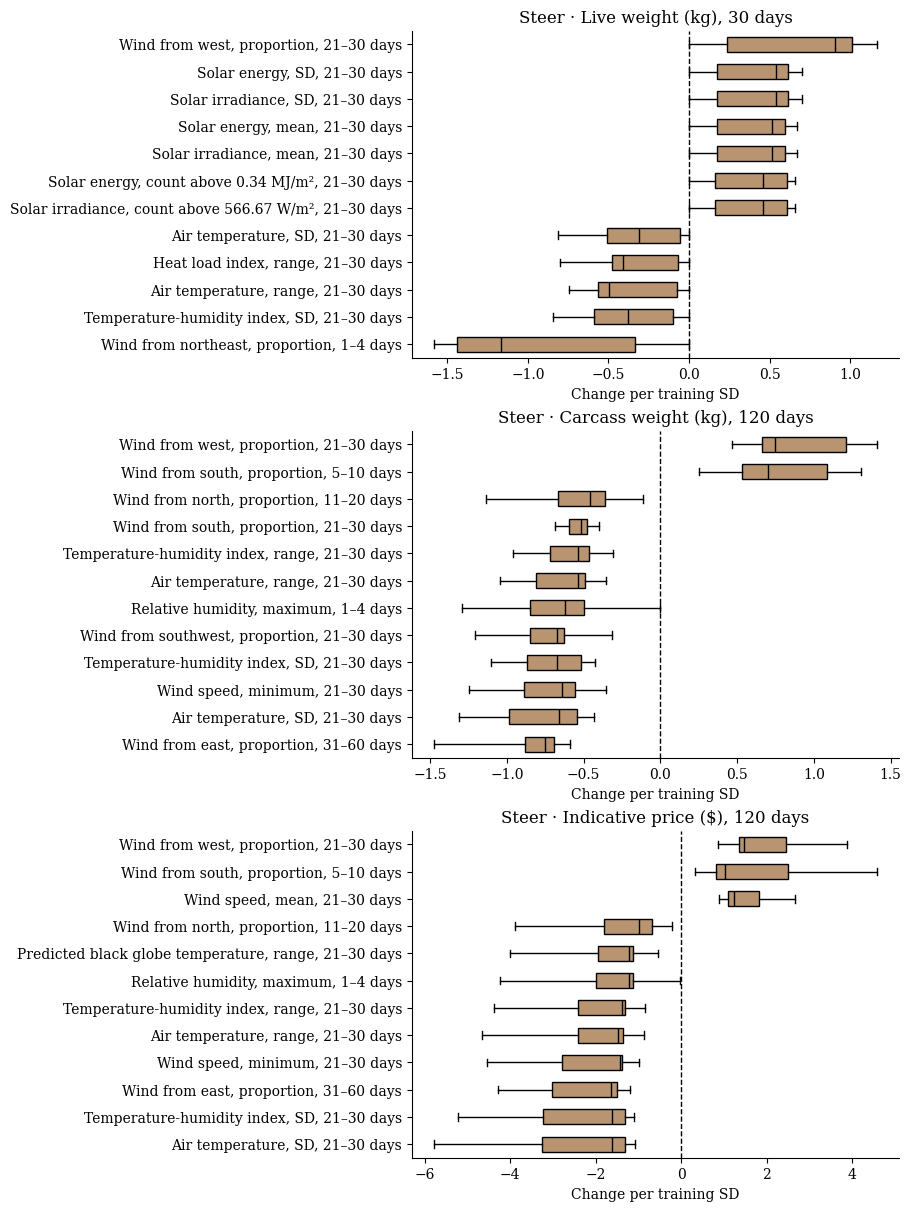

In [8]:
WINDOW_LABELS = {k:f"{v} days" for k,v in windows.items()}
weather_names = {"MnTemp(C)": "air temperature", "MnRH(%)": "relative humidity", "MnSpd(mps)": "wind speed",
                 "Rain(mm)": "rainfall", "RadGlb(MJ/m2)": "solar energy", "Average W/m2": "solar irradiance",
                 "Predicted BGT": "predicted black globe temperature", "THI": "temperature-humidity index",
                 "HLI": "heat load index", "Grazing HLI2": "grazing heat load index"}
units = {"MnTemp(C)": "°C", "Predicted BGT": "°C", "MnRH(%)": "%", "MnSpd(mps)": "m/s",
         "Rain(mm)": "mm", "Average W/m2": "W/m²", "RadGlb(MJ/m2)": "MJ/m²"}
directions = dict(zip("N NE E SE S SW W NW".split(), "north northeast east southeast south southwest west northwest".split()))

def feature_label(feature):
    base, window, stat = re.fullmatch(r"(.+)__win(\d+_\d+)_(.+)", feature).groups()
    if stat == "proportion":
        name, aggregation = f"Wind from {directions[base[5:]]}", "proportion"
    else:
        name = weather_names[base].capitalize()
        if stat.startswith("above"):
            aggregation = f"count above {float(stat[5:-6]):g} {units.get(base, '')}".rstrip()
        else:
            aggregation = {"min": "minimum", "max": "maximum", "mean": "mean", "std": "SD", "diff": "range"}[stat]
    return f"{name}, {aggregation}, {WINDOW_LABELS[window]}"

for animal,color in palette.items():
    fig,axes = plt.subplots(3,1,figsize=(9,12),layout="constrained")
    for ax,target,title in zip(axes,targets,titles):
        sub = coefficients.query("animal == @animal and target == @target")
        wide = sub.pivot(index="fold",columns="feature",values="coef")
        means = wide.loc[:,wide.count().ge(5)].mean()
        selected = means.loc[means.abs().nlargest(12).index].sort_values(ascending=False).index
        boxes(ax,[wide[k].dropna() for k in selected],[feature_label(k) for k in selected],color)
        ax.set(title=f"{animal.capitalize()} · {title}, {days[animal,target]} days",xlabel="Change per training SD")
    save(fig,f"elasticnet_coefficients_{animal}")